# Clasificación de enfermedades en hojas de papa con ResNet-18

Caso práctico de Inteligencia Artificial II.

## 1. Verificación del entorno

Comprobamos las versiones de las herramientas y la ejecución en GPU.

In [2]:
# Importamos las herramientas
import sys
import torch
import torchvision

# Mostramos qué Python está ejecutando el notebook.
print("Python utilizado:", sys.executable)

# Consultamos las versiones de las bibliotecas.
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

# Comprobamos si PyTorch puede acceder a la GPU mediante CUDA.
print("CUDA disponible:", torch.cuda.is_available())

Python utilizado: c:\Users\javip\OneDrive\Documentos\Trabajos\Resnet\.venv\Scripts\python.exe
PyTorch: 2.8.0+cu128
Torchvision: 0.23.0+cu128
CUDA disponible: True


In [4]:
# Creamos un tensor: un arreglo de números.
# device="cuda" indica que se guardará en la GPU.
x = torch.tensor([1.0, 2.0, 3.0], device="cuda")

# Multiplicamos cada elemento por dos usando la GPU.
resultado = x * 2

# Mostramos dónde está almacenado el tensor.
print("Dispositivo:", x.device)

# Copiamos el resultado a la memoria de la CPU para mostrarlo.
print("Resultado:", resultado.cpu())

Dispositivo: cuda:0
Resultado: tensor([2., 4., 6.])


## 2. Dataset: PlantVillage

Utilizamos imágenes RGB de hojas de papa de tres clases:
tizón temprano, tizón tardío y sana.

Primero comprobamos las cantidades disponibles por clase.

In [5]:
from pathlib import Path

# Indicamos dónde están las carpetas de imágenes.
ruta_datos = Path("data/raw")

# Comprobamos que la carpeta exista antes de leerla.
assert ruta_datos.exists(), "No se encontró la carpeta data/raw"

total = 0

# Cada subcarpeta representa una clase.
for carpeta in sorted(ruta_datos.iterdir()):
    if carpeta.is_dir():
        # Contamos únicamente archivos con extensiones de imagen.
        cantidad = sum(
            1 for archivo in carpeta.iterdir()
            if archivo.suffix.lower() in {".jpg", ".jpeg", ".png"}
        )
        print(f"{carpeta.name}: {cantidad} imágenes")
        total += cantidad

print(f"\nTotal: {total} imágenes")

Potato___Early_blight: 1000 imágenes
Potato___healthy: 152 imágenes
Potato___Late_blight: 1000 imágenes

Total: 2152 imágenes


### 2.1. Exploración visual

Mostramos tres ejemplos por clase para observar las imágenes y
comprobar que podemos abrirlas.

Las imágenes pertenecen a PlantVillage y proceden del repositorio
spMohanty/PlantVillage-Dataset en GitHub.

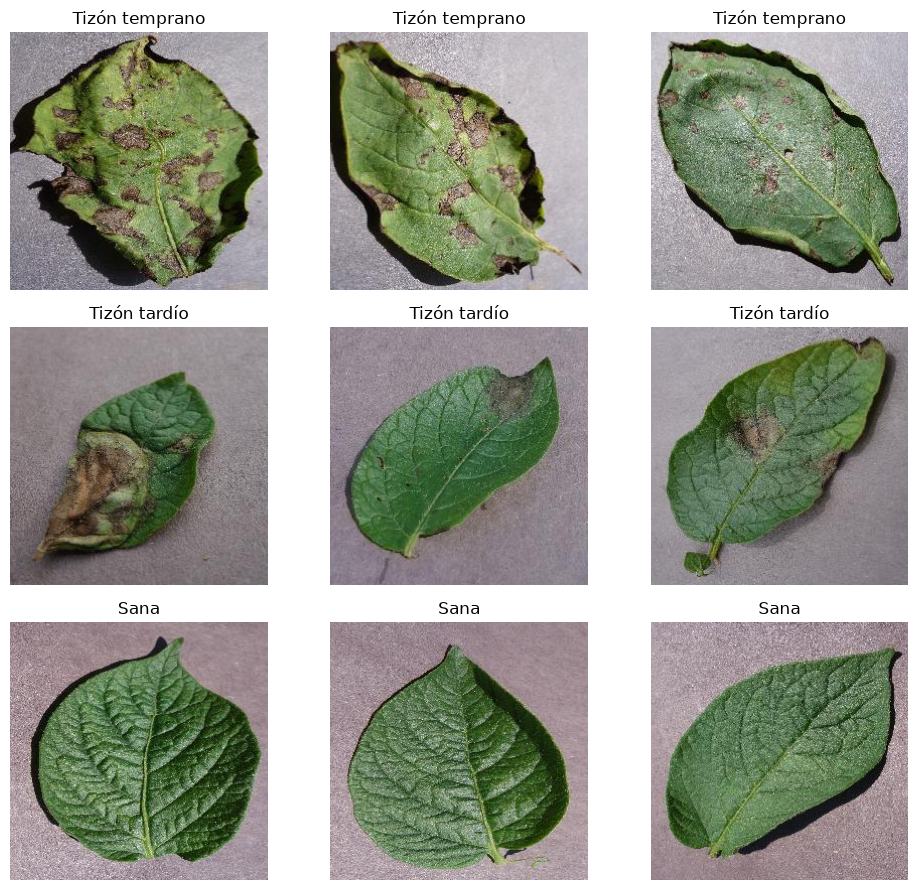

In [6]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Relacionamos los nombres de las carpetas con etiquetas en español.
clases = {
    "Potato___Early_blight": "Tizón temprano",
    "Potato___Late_blight": "Tizón tardío",
    "Potato___healthy": "Sana",
}

ruta_datos = Path("data/raw")

# Creamos una figura: una fila por clase y tres columnas de ejemplos.
fig, ejes = plt.subplots(3, 3, figsize=(10, 9))

for fila, (carpeta, etiqueta) in enumerate(clases.items()):
    # Ordenamos las imágenes para mostrar los mismos ejemplos al repetir.
    archivos = sorted(
        archivo for archivo in (ruta_datos / carpeta).iterdir()
        if archivo.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )

    for columna, ruta_imagen in enumerate(archivos[:3]):
        # Abrimos cada imagen y la mostramos en formato RGB.
        with Image.open(ruta_imagen) as imagen:
            ejes[fila, columna].imshow(imagen.convert("RGB"))

        ejes[fila, columna].set_title(etiqueta)
        ejes[fila, columna].axis("off")

# Ajustamos los espacios entre las imágenes.
plt.tight_layout()

# Guardamos la figura
ruta_resultados = Path("resultados")
ruta_resultados.mkdir(exist_ok=True)
fig.savefig(ruta_resultados / "ejemplos_dataset.png", dpi=150)

plt.show()

## 3. Preparación de los datos

### 3.1. Revisión de imágenes

Comprobamos que las imágenes puedan leerse y buscamos duplicados
exactos mediante SHA-256, una huella calculada a partir de cada archivo.

In [7]:
import hashlib

# Reunimos las rutas de las imágenes de las tres clases.
rutas_imagenes = []

for carpeta in clases:
    for ruta in sorted((ruta_datos / carpeta).iterdir()):
        if ruta.is_file() and ruta.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            rutas_imagenes.append(ruta)

no_legibles = []
duplicados = []
huellas = {}

for ruta in rutas_imagenes:
    # Intentamos abrir y leer completamente la imagen.
    try:
        with Image.open(ruta) as imagen:
            imagen.load()
    except Exception as error:
        no_legibles.append((str(ruta), str(error)))
        continue

    # Calculamos la huella del contenido del archivo.
    huella = hashlib.sha256(ruta.read_bytes()).hexdigest()

    # Si la huella ya existe, encontramos un archivo idéntico.
    if huella in huellas:
        duplicados.append((str(huellas[huella]), str(ruta)))
    else:
        huellas[huella] = ruta

print("Archivos revisados:", len(rutas_imagenes))
print("Imágenes no legibles:", len(no_legibles))
print("Duplicados exactos:", len(duplicados))

Archivos revisados: 2152
Imágenes no legibles: 0
Duplicados exactos: 0


### 3.2. Identificación de hojas

Consultamos leaf-map.json para identificar las fotografías que
pertenecen a una misma hoja.

Todas las fotografías de una hoja deben quedar en la misma
partición: entrenamiento, validación o prueba.

In [8]:
import json

# Leemos el mapa que relaciona nombres de imágenes con hojas.
with open("data/leaf-map.json", encoding="utf-8") as archivo:
    mapa_hojas = json.load(archivo)

registros = []
sin_identificador = []

for ruta in rutas_imagenes:
    # Obtenemos la parte del nombre que utiliza el mapa.
    # stem elimina la extensión; lower convierte a minúsculas.
    nombre_base = ruta.stem.lower().split("___")[-1].strip()

    # Buscamos los identificadores asociados a ese nombre.
    coincidencias = mapa_hojas.get(nombre_base, [])

    # Conservamos los identificadores de la clase correspondiente.
    identificadores = {
        codigo for codigo in coincidencias
        if codigo.startswith(ruta.parent.name + ":::")
    }

    if len(identificadores) == 1:
        # Extraemos el identificador único de esa hoja.
        hoja = next(iter(identificadores))

        # Registramos la ruta, la clase y la hoja de cada imagen.
        registros.append({
            "ruta": str(ruta),
            "clase": ruta.parent.name,
            "hoja": hoja,
        })
    else:
        sin_identificador.append(str(ruta))

# Un conjunto elimina repeticiones y permite contar hojas distintas.
hojas_distintas = {registro["hoja"] for registro in registros}

print("Imágenes con identificador:", len(registros))
print("Imágenes sin identificador único:", len(sin_identificador))
print("Hojas distintas:", len(hojas_distintas))

# Detenemos el proceso si alguna imagen quedó sin identificar.
assert len(registros) == len(rutas_imagenes), "Falta revisar identificadores"

Imágenes con identificador: 2152
Imágenes sin identificador único: 0
Hojas distintas: 538


### 3.3. División de los datos por hojas y clases

Asignamos aproximadamente el 60 % de las hojas a entrenamiento,
el 20 % a validación y el 20 % a prueba.

Realizamos el reparto por clase y mantenemos juntas todas las
fotografías de una misma hoja. Fijamos la semilla 42 para que
la asignación pueda repetirse.

In [10]:
import random
from math import ceil

# Asociamos cada hoja con su clase.
clase_por_hoja = {
    registro["hoja"]: registro["clase"]
    for registro in registros
}

# Fijamos la semilla para repetir la misma división.
generador = random.Random(42)

# Creamos listas vacías para las tres particiones.
hojas_train = []
hojas_val = []
hojas_test = []

# Dividimos las hojas de cada clase por separado.
for carpeta in sorted(clases):
    hojas_clase = sorted(
        hoja for hoja, clase in clase_por_hoja.items()
        if clase == carpeta
    )

    # Mezclamos las hojas aleatoriamente.
    generador.shuffle(hojas_clase)

    # Reservamos aproximadamente un 20 % para cada evaluación.
    # Redondeamos hacia arriba porque necesitamos hojas completas.
    cantidad_reservada = ceil(len(hojas_clase) * 0.20)

    # Asignamos las primeras hojas a validación.
    hojas_val.extend(hojas_clase[:cantidad_reservada])

    # Asignamos las siguientes hojas a prueba.
    hojas_test.extend(
        hojas_clase[cantidad_reservada:2 * cantidad_reservada]
    )

    # Asignamos las restantes a entrenamiento.
    hojas_train.extend(hojas_clase[2 * cantidad_reservada:])

# Comprobamos que ninguna hoja aparezca en dos particiones.
assert set(hojas_train).isdisjoint(hojas_val)
assert set(hojas_train).isdisjoint(hojas_test)
assert set(hojas_val).isdisjoint(hojas_test)

# Comprobamos que todas las hojas estén asignadas.
assert (
    set(hojas_train) | set(hojas_val) | set(hojas_test)
) == set(clase_por_hoja)

# Estas impresiones están fuera del ciclo y se ejecutan una sola vez.
print("Hojas de entrenamiento:", len(hojas_train))
print("Hojas de validación:", len(hojas_val))
print("Hojas de prueba:", len(hojas_test))

Hojas de entrenamiento: 322
Hojas de validación: 108
Hojas de prueba: 108
